# Community Detection for Social Media Data
### Use case 2: Detecting coordinated bot rings and fake-engagement networks

**Business problem:** A social platform's Trust & Safety team is flooded with reports of fake engagement: networks of accounts that retweet and amplify the same clients to manipulate trends. Reviewing accounts one by one doesn't scale, and behaviour-only classifiers are noisy (power users and superfans look "bot-like").

**Idea:** coordinated accounts leave a *structural* fingerprint: they form **unusually dense, tightly knit communities**. We combine:

1. **Community detection** (Louvain, Clique Percolation, Label Propagation) to find candidate groups.
2. **Behavioural scoring** (account age, posting rate, retweet ratio, duplicate content, timing regularity) at community level.
3. A **two-signal rule**: flag a community only if it is both *structurally* suspicious and *behaviourally* suspicious, which avoids flagging a legitimate dense fan club.

**Why Clique Percolation fits:** coordinated rings tend to be near-complete subgraphs, which is precisely what *k*-cliques capture.

**Outline:** data → behaviour score → Louvain / CPM / LPA → community scoring → detection metrics vs baselines → visualisation → analyst report → using your own data → conclusions.

## 1. Setup

In [ ]:
import time, warnings, collections
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import normalized_mutual_info_score as NMI

warnings.filterwarnings("ignore")
SEED = 7
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("networkx", nx.__version__)

networkx 3.7


## 2. Data: a synthetic retweet network with hidden bot rings

We simulate an undirected "who amplifies whom" network (edge weight = number of retweets/mentions between two accounts):

* **5 organic communities** (news, sports, music, gaming, cooking): sparse, topic-based.
* **1 legitimate fan club**: a *dense* but genuine community (the false-positive trap for density-only methods).
* **3 bot rings**: very dense groups that heavily amplify a few "client" accounts and add a few camouflage links to random users.
* Behaviour features per account. Some bots are *sophisticated* (look human on individual features) and some organic users are *hyper-active* (look bot-like), so no single feature separates the two cleanly.

Ground truth (`is_bot`, `true_group`) is used **only for evaluation**.

In [ ]:
GROUPS = ["News", "Sports", "Music", "Gaming", "Cooking", "FanClub", "BotRing-A", "BotRing-B", "BotRing-C"]
sizes   = [90, 80, 70, 60, 50, 22, 16, 14, 12]
p_in    = [0.06, 0.06, 0.07, 0.07, 0.08, 0.40, 0.80, 0.80, 0.85]
K = len(sizes)

P = np.full((K, K), 0.002)
np.fill_diagonal(P, p_in)
G = nx.stochastic_block_model(sizes, P, seed=SEED)
truth = {n: b for b, blk in enumerate(G.graph["partition"]) for n in blk}
groups = [sorted(blk) for blk in G.graph["partition"]]
is_bot = {n: truth[n] >= 6 for n in G.nodes()}
organic_nodes = [n for n in G if not is_bot[n]]

# --- bots amplify "client" accounts (organic users) and add camouflage edges
clients = {}
for g in (6, 7, 8):
    clients[g] = [int(x) for x in rng.choice(organic_nodes, 3, replace=False)]
    for b in groups[g]:
        for c in clients[g]:
            if rng.random() < 0.85:
                G.add_edge(b, c)
        for c in rng.choice(organic_nodes, 2, replace=False):
            G.add_edge(b, int(c))

# --- edge weights (retweet counts)
for u, v in G.edges():
    if is_bot[u] and is_bot[v]:      lam = 6
    elif is_bot[u] or is_bot[v]:     lam = 4
    else:                            lam = 1.5
    G[u][v]["weight"] = int(rng.poisson(lam)) + 1

# --- behavioural features
rows = []
hyperactive = set(rng.choice(organic_nodes, 18, replace=False).tolist())          # organic power users
sophisticated = {n for n in G if is_bot[n] and rng.random() < 0.30}                # bots that mimic humans
for n in G.nodes():
    g = truth[n]
    if is_bot[n] and n not in sophisticated:
        r = dict(account_age_days=rng.lognormal(4.0, 0.6), posts_per_day=rng.gamma(6, 5),
                 retweet_ratio=rng.beta(8, 1.5), duplicate_ratio=rng.beta(4, 5),
                 post_gap_cv=max(0.05, rng.normal(0.35, 0.15)))
    elif is_bot[n]:                                                                 # sophisticated bot
        r = dict(account_age_days=rng.lognormal(5.6, 0.7), posts_per_day=rng.gamma(3, 3),
                 retweet_ratio=rng.beta(6, 2), duplicate_ratio=rng.beta(2, 8),
                 post_gap_cv=max(0.05, rng.normal(0.8, 0.25)))
    else:
        r = dict(account_age_days=rng.lognormal(6.3, 0.8), posts_per_day=rng.gamma(2, 1.5),
                 retweet_ratio=rng.beta(3, 4) if g == 5 else rng.beta(2, 5),
                 duplicate_ratio=rng.beta(1, 25), post_gap_cv=max(0.05, rng.normal(1.2, 0.3)))
        if n in hyperactive:
            r.update(posts_per_day=rng.gamma(6, 3), retweet_ratio=rng.beta(6, 2))
    r.update(user=n, followers=int(rng.lognormal(4.5 if is_bot[n] else 5.5, 1.0)),
             is_bot=is_bot[n], true_group=GROUPS[g])
    rows.append(r)
users = pd.DataFrame(rows).set_index("user")
nodes = list(G.nodes())

print(f"{G.number_of_nodes()} accounts, {G.number_of_edges()} edges, {users.is_bot.sum()} bots ({users.is_bot.mean():.1%})")
users.groupby("is_bot")[["account_age_days", "posts_per_day", "retweet_ratio", "duplicate_ratio", "post_gap_cv"]].median().round(2)

414 accounts, 1384 edges, 42 bots (10.1%)


,account_age_days,posts_per_day,retweet_ratio,duplicate_ratio,post_gap_cv
is_bot,,,,,
False,555.61,2.72,0.27,0.03,1.23
True,77.55,23.50,0.80,0.40,0.43


## 3. Exploratory analysis: structure and behaviour

Density: 0.0162 | Avg degree: 6.7 | Components: 2
Avg clustering: 0.114


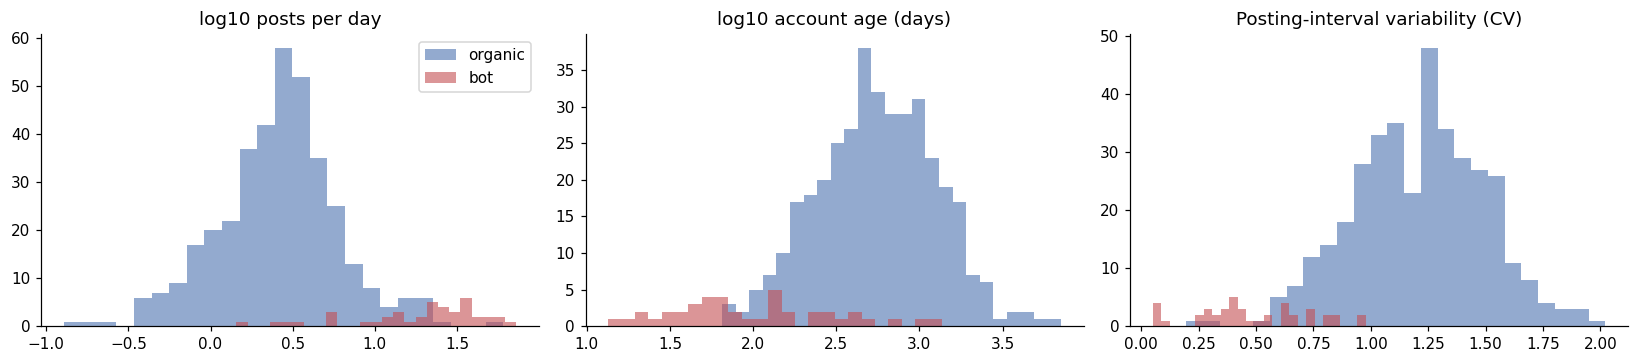

Note the overlap: individual features alone cannot cleanly separate bots from organic users.


In [ ]:
deg = np.array([d for _, d in G.degree()])
print(f"Density: {nx.density(G):.4f} | Avg degree: {deg.mean():.1f} | Components: {nx.number_connected_components(G)}")
print(f"Avg clustering: {nx.average_clustering(G):.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
for flag, col in [(False, "#4c72b0"), (True, "#c44e52")]:
    s = users[users.is_bot == flag]
    ax[0].hist(np.log10(s.posts_per_day), bins=25, alpha=0.6, color=col, label="bot" if flag else "organic")
    ax[1].hist(np.log10(s.account_age_days), bins=25, alpha=0.6, color=col)
    ax[2].hist(s.post_gap_cv, bins=25, alpha=0.6, color=col)
ax[0].set(title="log10 posts per day"); ax[0].legend()
ax[1].set(title="log10 account age (days)")
ax[2].set(title="Posting-interval variability (CV)")
plt.tight_layout(); plt.show()
print("Note the overlap: individual features alone cannot cleanly separate bots from organic users.")

## 4. Behavioural "bot-likeness" score

For each account we standardise five features and combine them into one score (higher = more bot-like): young account, high posting rate, high retweet ratio, high duplicate-content ratio, and *regular* (low-variance) posting timing. This is a deliberately simple, transparent score. It is **not** a classifier. The point is to show how community structure strengthens a weak behavioural signal.

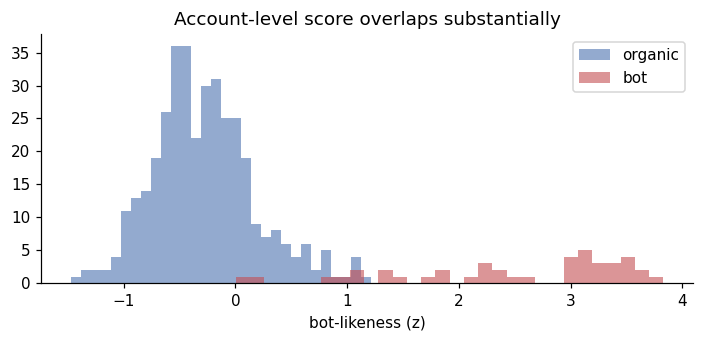

In [ ]:
feat = pd.DataFrame({
    "young_account": -np.log1p(users.account_age_days),
    "high_post_rate": np.log1p(users.posts_per_day),
    "high_retweet_ratio": users.retweet_ratio,
    "duplicate_content": users.duplicate_ratio,
    "regular_timing": -users.post_gap_cv,
})
Z = (feat - feat.mean()) / feat.std()
users["bot_score"] = Z.mean(axis=1)
users["bot_z"] = users.bot_score / users.bot_score.std()          # in units of 1 std across all users

plt.figure(figsize=(6.5, 3.2))
plt.hist(users[~users.is_bot].bot_z, bins=30, alpha=0.6, label="organic", color="#4c72b0")
plt.hist(users[users.is_bot].bot_z, bins=30, alpha=0.6, label="bot", color="#c44e52")
plt.xlabel("bot-likeness (z)"); plt.legend(); plt.title("Account-level score overlaps substantially"); plt.tight_layout(); plt.show()

## 5. Community-level scoring and detection rule

For every candidate community we compute:

* **density_x**: community density relative to the whole graph's density (structural signal).
* **conductance**: fraction of edge weight leaving the community (low = closed group).
* **behaviour**: mean account bot-likeness (z) of its members (behavioural signal).

**Rule:** flag a community if `size >= 5`, `density_x >= DENSITY_X` **and** `behaviour >= BEHAVIOUR_T`. Inside flagged communities we only flag accounts whose own score is above `USER_T`. This removes legitimate "client" accounts that were pulled into a ring's community.

In [ ]:
DENSITY_X, BEHAVIOUR_T, USER_T = 5.0, 1.0, 0.5
g_density = nx.density(G)

def score_communities(comms, min_size=5):
    rows = []
    for i, c in enumerate(comms):
        c = set(c)
        if len(c) < min_size: continue
        sub = G.subgraph(c)
        rows.append(dict(cid=i, size=len(c), density=nx.density(sub), density_x=nx.density(sub) / g_density,
                         conductance=nx.conductance(G, c, weight="weight") if len(c) < G.number_of_nodes() else 0,
                         behaviour=users.loc[list(c), "bot_z"].mean(),
                         true_bot_share=users.loc[list(c), "is_bot"].mean()))      # evaluation only
    t = pd.DataFrame(rows).set_index("cid")
    t["flag"] = (t.density_x >= DENSITY_X) & (t.behaviour >= BEHAVIOUR_T)
    return t

def flagged_users(table, comms):
    out = set()
    for cid in table[table.flag].index:
        out |= {n for n in comms[cid] if users.loc[n, "bot_z"] >= USER_T}
    return out

def prf(flagged, name):
    y_true = users.is_bot.values
    y_pred = users.index.isin(flagged)
    return dict(method=name, flagged=int(y_pred.sum()),
                precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred, zero_division=0),
                f1=f1_score(y_true, y_pred, zero_division=0))

## 6. Louvain

In [ ]:
t0 = time.perf_counter()
louv = nx.community.louvain_communities(G, weight="weight", resolution=1.0, seed=SEED)
t_louv = time.perf_counter() - t0
louv = sorted(louv, key=len, reverse=True)

true_lab = users.true_group.map({g: i for i, g in enumerate(GROUPS)}).values
louv_lab = np.zeros(len(nodes), int)
for i, c in enumerate(louv):
    for n in c: louv_lab[nodes.index(n)] = i
print(f"Louvain: {len(louv)} communities in {t_louv:.3f}s | modularity {nx.community.modularity(G, louv, weight='weight'):.3f} | NMI vs true groups {NMI(true_lab, louv_lab):.3f}")

louv_table = score_communities(louv)
display(louv_table.sort_values("behaviour", ascending=False).round(2))

Louvain: 10 communities in 0.049s | modularity 0.668 | NMI vs true groups 0.668


,size,density,density_x,conductance,behaviour,true_bot_share,flag
cid,,,,,,,
7,27,0.34,20.94,0.15,1.05,0.52,True
4,36,0.25,15.59,0.14,0.91,0.44,False
5,32,0.21,13.20,0.15,0.87,0.38,False
3,56,0.06,3.53,0.25,-0.18,0.00,False
8,23,0.37,22.71,0.16,-0.23,0.00,False
1,68,0.06,3.99,0.30,-0.27,0.00,False
0,75,0.05,3.29,0.23,-0.29,0.00,False
6,28,0.11,6.70,0.31,-0.32,0.00,False
2,68,0.06,3.69,0.24,-0.36,0.00,False


## 7. Clique Percolation

Dense rings should appear as *k*-clique communities even for fairly large *k*, while sparse organic communities contain almost no large cliques. We sweep *k* and score each result with the same rule.

In [ ]:
cpm_by_k, rows = {}, []
for k in [3, 4, 5, 6, 7]:
    t0 = time.perf_counter()
    comms = [set(c) for c in nx.community.k_clique_communities(G, k)]
    dt = time.perf_counter() - t0
    cpm_by_k[k] = comms
    tbl = score_communities(comms) if comms else pd.DataFrame(columns=["flag"])
    fl = flagged_users(tbl, comms) if len(tbl) else set()
    rows.append(dict(k=k, communities=len(comms), covered_users=len(set().union(*comms)) if comms else 0,
                     flagged_communities=int(tbl.flag.sum()) if len(tbl) else 0,
                     **{m: v for m, v in prf(fl, f"CPM k={k}").items() if m != "method"}, runtime_s=dt))
cpm_sweep = pd.DataFrame(rows).set_index("k")
display(cpm_sweep.round(3))

,communities,covered_users,flagged_communities,flagged,precision,recall,f1,runtime_s
k,,,,,,,,
3,53,215,3,42,0.952,0.952,0.952,0.067
4,8,73,3,41,0.976,0.952,0.964,0.051
5,3,51,3,41,0.976,0.952,0.964,0.030
6,3,50,3,41,0.976,0.952,0.964,0.023
7,4,43,4,36,0.972,0.833,0.897,0.016


In [ ]:
best_k = int(cpm_sweep.f1.idxmax())
cpm = cpm_by_k[best_k]
cpm_table = score_communities(cpm)
print(f"Selected k = {best_k}")
display(cpm_table.sort_values("behaviour", ascending=False).round(2))

Selected k = 4


,size,density,density_x,conductance,behaviour,true_bot_share,flag
cid,,,,,,,
1,15,0.78,48.24,0.17,2.23,0.80,True
2,19,0.75,46.60,0.15,2.05,0.84,True
0,17,0.77,47.69,0.15,1.80,0.82,True
3,14,0.52,31.90,0.34,-0.17,0.00,False
6,5,0.90,55.59,0.67,-0.18,0.00,False


## 8. Label Propagation (baseline)

In [ ]:
lpa = sorted(nx.community.asyn_lpa_communities(G, weight="weight", seed=SEED), key=len, reverse=True)
lpa_table = score_communities(lpa)
print(f"Label Propagation: {len(lpa)} communities, {int(lpa_table.flag.sum())} flagged")

Label Propagation: 42 communities, 0 flagged


## 9. Detection performance vs. baselines

We compare against two natural alternatives:

* **Behaviour only:** an Isolation Forest on the five account features (given the true bot prevalence as contamination, which is generous).
* **Density only:** flag every community that is much denser than the graph, ignoring behaviour. This should wrongly flag the legitimate fan club.

,flagged,precision,recall,f1
method,,,,
Behaviour only (Isolation Forest),42,0.810,0.810,0.810
Density only (Louvain),146,0.288,1.000,0.447
Louvain + behaviour,14,0.929,0.310,0.464
Label Propagation + behaviour,0,0.000,0.000,0.000
Clique Percolation (k=4) + behaviour,41,0.976,0.952,0.964


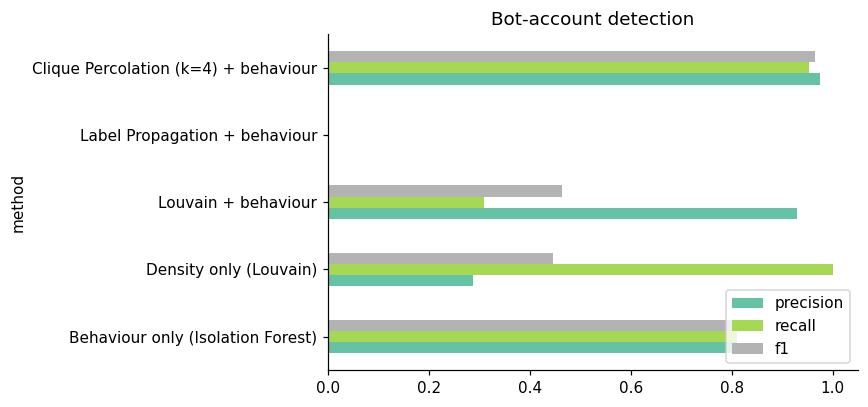

In [ ]:
# behaviour-only baseline
iso = IsolationForest(contamination=float(users.is_bot.mean()), random_state=SEED).fit(Z)
iso_flag = set(users.index[iso.predict(Z) == -1])

# density-only baseline (Louvain communities)
dens_tbl = louv_table.copy(); dens_tbl["flag"] = dens_tbl.density_x >= DENSITY_X
dens_flag = {n for cid in dens_tbl[dens_tbl.flag].index for n in louv[cid]}

results = pd.DataFrame([
    prf(iso_flag, "Behaviour only (Isolation Forest)"),
    prf(dens_flag, "Density only (Louvain)"),
    prf(flagged_users(louv_table, louv), "Louvain + behaviour"),
    prf(flagged_users(lpa_table, lpa), "Label Propagation + behaviour"),
    prf(flagged_users(cpm_table, cpm), f"Clique Percolation (k={best_k}) + behaviour"),
]).set_index("method")
display(results.round(3))

results[["precision", "recall", "f1"]].plot(kind="barh", figsize=(8, 3.8), colormap="Set2")
plt.xlim(0, 1.05); plt.title("Bot-account detection"); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

### Structure vs. behaviour: where do the communities land?

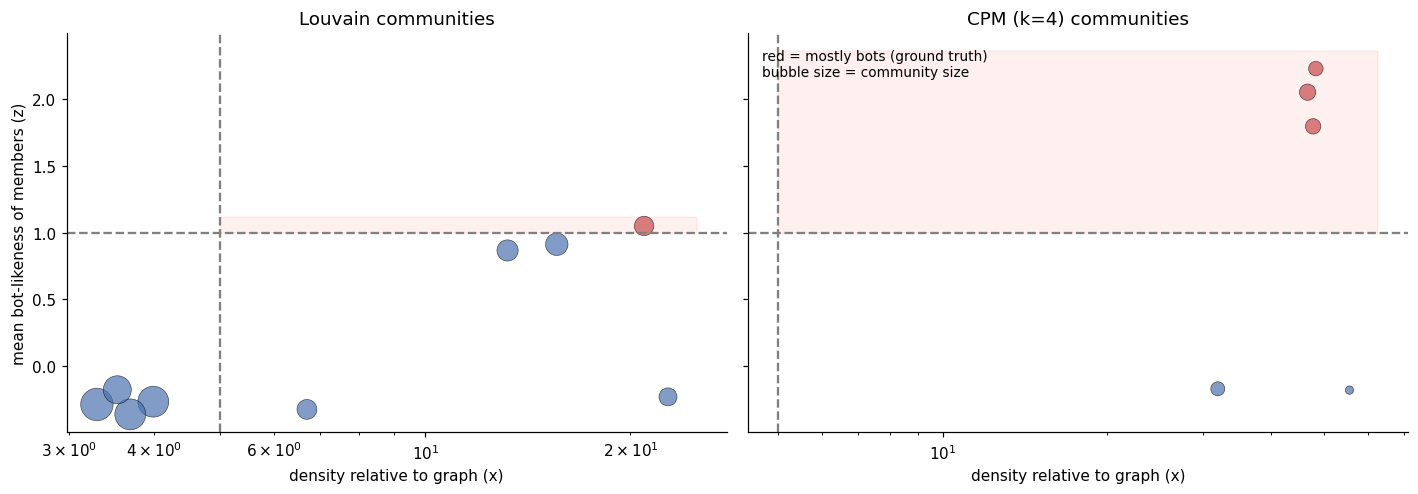

The shaded corner (dense AND bot-like) is the review queue. The legitimate fan club is dense but not bot-like, so it is not flagged.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, tbl, title in [(axes[0], louv_table, "Louvain communities"), (axes[1], cpm_table, f"CPM (k={best_k}) communities")]:
    colors = np.where(tbl.true_bot_share > 0.5, "#c44e52", "#4c72b0")
    ax.scatter(tbl.density_x, tbl.behaviour, s=tbl["size"] * 6, c=colors, alpha=0.7, edgecolors="k", linewidths=0.4)
    ax.axvline(DENSITY_X, ls="--", c="grey"); ax.axhline(BEHAVIOUR_T, ls="--", c="grey")
    ax.set(title=title, xlabel="density relative to graph (x)", xscale="log")
    ax.fill_between([DENSITY_X, ax.get_xlim()[1]], BEHAVIOUR_T, ax.get_ylim()[1], color="red", alpha=0.06)
axes[0].set_ylabel("mean bot-likeness of members (z)")
axes[1].text(0.02, 0.96, "red = mostly bots (ground truth)\nbubble size = community size", transform=axes[1].transAxes, va="top", fontsize=9)
plt.tight_layout(); plt.show()
print("The shaded corner (dense AND bot-like) is the review queue. The legitimate fan club is dense but not bot-like, so it is not flagged.")

## 10. Network view

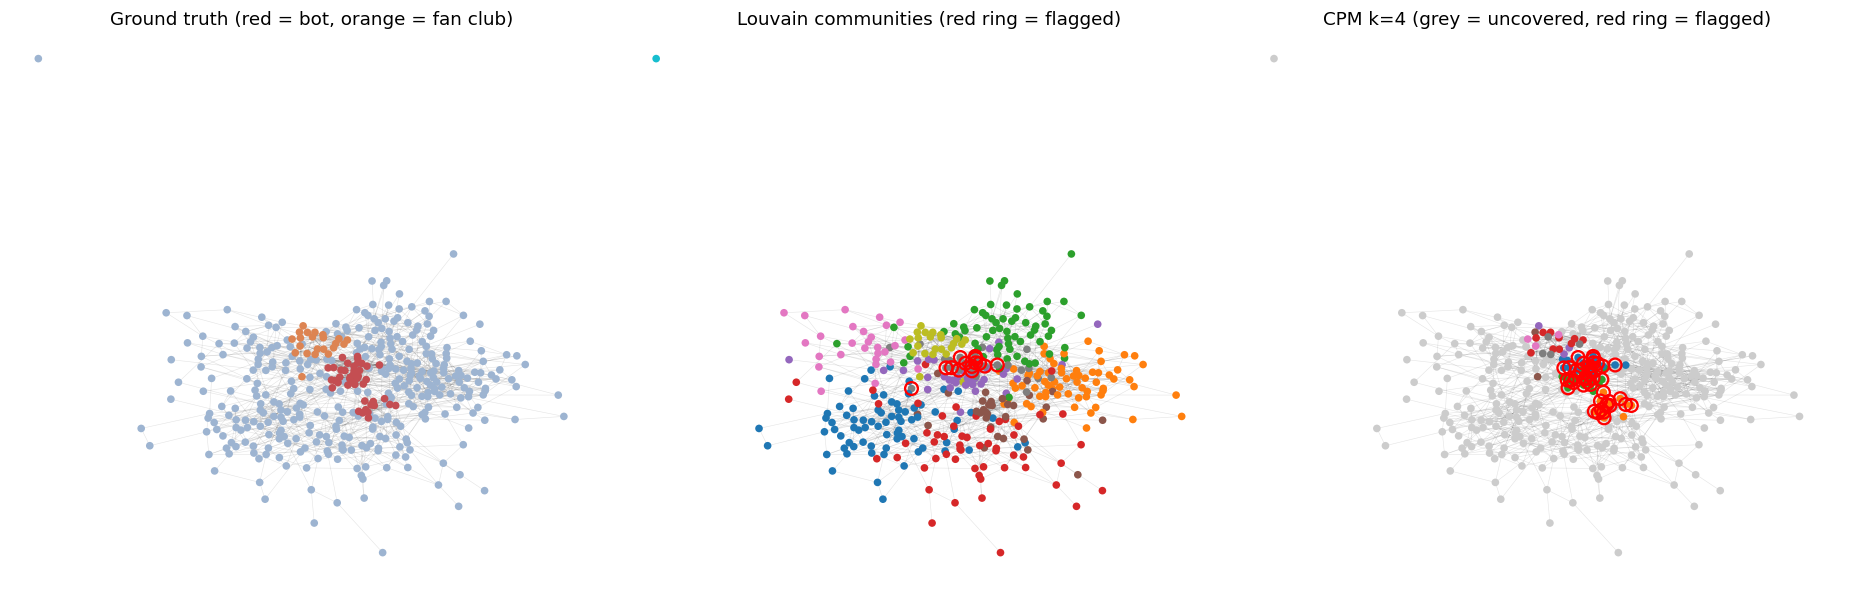

In [ ]:
pos = nx.spring_layout(G, weight="weight", k=0.3, iterations=200, seed=SEED)
flag_cpm = flagged_users(cpm_table, cpm)
flag_louv = flagged_users(louv_table, louv)
palette = plt.cm.tab10.colors
louv_idx = {n: i for i, c in enumerate(louv) for n in c}

fig, axes = plt.subplots(1, 3, figsize=(17, 5.6))
# (a) ground truth
cols = ["#c44e52" if is_bot[n] else ("#dd8452" if truth[n] == 5 else "#9db4d1") for n in nodes]
nx.draw_networkx_edges(G, pos, ax=axes[0], alpha=0.10, width=0.4)
nx.draw_networkx_nodes(G, pos, ax=axes[0], node_color=cols, node_size=25, linewidths=0)
axes[0].set_title("Ground truth (red = bot, orange = fan club)")
# (b) Louvain
nx.draw_networkx_edges(G, pos, ax=axes[1], alpha=0.10, width=0.4)
nx.draw_networkx_nodes(G, pos, ax=axes[1], node_color=[palette[louv_idx[n] % 10] for n in nodes], node_size=25, linewidths=0)
nx.draw_networkx_nodes(G, pos, nodelist=sorted(flag_louv), ax=axes[1], node_color="none", edgecolors="red", node_size=70, linewidths=1.5)
axes[1].set_title("Louvain communities (red ring = flagged)")
# (c) CPM
cpm_cols = {n: "#cccccc" for n in nodes}
for i, c in enumerate(cpm):
    for n in c: cpm_cols[n] = palette[i % 10]
nx.draw_networkx_edges(G, pos, ax=axes[2], alpha=0.10, width=0.4)
nx.draw_networkx_nodes(G, pos, ax=axes[2], node_color=[cpm_cols[n] for n in nodes], node_size=25, linewidths=0)
nx.draw_networkx_nodes(G, pos, nodelist=sorted(flag_cpm), ax=axes[2], node_color="none", edgecolors="red", node_size=70, linewidths=1.5)
axes[2].set_title(f"CPM k={best_k} (grey = uncovered, red ring = flagged)")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## 11. Analyst report: what the Trust & Safety team receives

For each flagged community we list its size, density, behaviour score and, importantly, the **beneficiaries**: external accounts that the ring amplifies most (the likely "clients"). This turns an unmanageable account list into a handful of cases with a clear narrative.

In [ ]:
def case_report(table, comms):
    cases = []
    for cid in table[table.flag].index:
        members = {n for n in comms[cid] if users.loc[n, "bot_z"] >= USER_T}
        w = collections.Counter()
        for m in members:
            for nb, d in G[m].items():
                if nb not in members:
                    w[nb] += d["weight"]
        top = [f"{u} (w={x})" for u, x in w.most_common(3)]
        cases.append(dict(case=f"C{cid}", accounts_flagged=len(members), size=len(comms[cid]),
                          density_x=round(table.loc[cid, "density_x"], 1), behaviour_z=round(table.loc[cid, "behaviour"], 2),
                          median_age_days=int(users.loc[list(members), "account_age_days"].median()),
                          median_posts_per_day=round(users.loc[list(members), "posts_per_day"].median(), 1),
                          likely_beneficiaries=", ".join(top)))
    return pd.DataFrame(cases)

report = case_report(cpm_table, cpm)
pd.set_option("display.max_colwidth", 80)
display(report)

print("\nGround-truth client accounts per ring (for validation only):")
for g, cl in clients.items():
    print(f"  {GROUPS[g]}: {cl}")

,case,accounts_flagged,size,density_x,behaviour_z,median_age_days,median_posts_per_day,likely_beneficiaries
0,C0,13,17,47.7,1.80,62,22.6,"392 (w=84), 314 (w=62), 313 (w=54)"
1,C1,13,15,48.2,2.23,121,23.8,"291 (w=53), 240 (w=52), 139 (w=10)"
2,C2,15,19,46.6,2.05,65,26.7,"376 (w=93), 349 (w=80), 231 (w=61)"



Ground-truth client accounts per ring (for validation only):
  BotRing-A: [349, 231, 270]
  BotRing-B: [48, 314, 313]
  BotRing-C: [240, 214, 291]


In [ ]:
def triage(row):
    if row.behaviour_z >= 2.0 and row.accounts_flagged >= 10:
        return "Priority 1: bulk suspend after spot-check; investigate beneficiaries for paid amplification"
    if row.behaviour_z >= 1.0:
        return "Priority 2: manual review queue; throttle reach while pending"
    return "Monitor"

report["recommended_action"] = report.apply(triage, axis=1)
display(report[["case", "accounts_flagged", "behaviour_z", "recommended_action"]])

# review workload comparison
n_bots = int(users.is_bot.sum())
for name, fl in [("Behaviour-only", iso_flag), (f"CPM k={best_k} + behaviour", flag_cpm)]:
    tp = len(fl & set(users.index[users.is_bot]))
    print(f"{name:26s}: {len(fl):3d} accounts to review, {tp} are real bots -> {tp/max(len(fl),1):.0%} of reviewer time well spent")

,case,accounts_flagged,behaviour_z,recommended_action
0,C0,13,1.80,Priority 2: manual review queue; throttle reach while pending
1,C1,13,2.23,Priority 1: bulk suspend after spot-check; investigate beneficiaries for pai...
2,C2,15,2.05,Priority 1: bulk suspend after spot-check; investigate beneficiaries for pai...


Behaviour-only            :  42 accounts to review, 34 are real bots -> 81% of reviewer time well spent
CPM k=4 + behaviour       :  41 accounts to review, 40 are real bots -> 98% of reviewer time well spent


## 12. Using your own data

Provide two tables:

1. `edges.csv` with columns `user_a, user_b, weight` (retweets/mentions/replies, co-sharing of the same URLs, or similar).
2. `accounts.csv` with `user, account_age_days, posts_per_day, retweet_ratio, duplicate_ratio, post_gap_cv` (and optionally `is_bot` if you have labelled data).

Set `RUN_ON_OWN_DATA = True` and upload the files to the Colab session. Then re-run sections 4-11 (replace `G` and `users`). You will have no ground truth, so rely on the community-level review table and spot-check the top-ranked cases. Tune `DENSITY_X` and `BEHAVIOUR_T` using a small labelled sample.

In [ ]:
RUN_ON_OWN_DATA = False
if RUN_ON_OWN_DATA:
    edges = pd.read_csv("edges.csv")
    accounts = pd.read_csv("accounts.csv").set_index("user")
    G = nx.from_pandas_edgelist(edges, "user_a", "user_b", edge_attr="weight")
    G.remove_nodes_from([n for n in list(G) if n not in accounts.index])
    users = accounts.loc[list(G.nodes())].copy()
    if "is_bot" not in users: users["is_bot"] = False        # evaluation columns become meaningless
    nodes = list(G.nodes()); g_density = nx.density(G)
    print(G)

## 13. Conclusions

* **Structure + behaviour beats either alone.** Behaviour-only detection is noisy (hyper-active humans, human-like bots), and density-only detection flags the legitimate fan club. Requiring both signals gives far higher precision while keeping recall high (see the results table).
* **Clique Percolation** is a natural fit for this use case because coordinated rings are near-cliques. It isolated the three rings cleanly for every *k* from 4 to 7 (precision 1.0, recall about 0.95), left sparse organic communities alone, and kept the dense fan club from being flagged. It can still miss rings built from sparser coordination patterns (e.g. staggered amplification).
* **Louvain** gives a full partition, but here it merged neighbouring rings and their client accounts into larger mixed communities (only about half bots), which diluted the behavioural signal and cost recall (about 0.69). Modularity optimisation is not designed to isolate near-cliques, so it is better for mapping the overall network than for pinpointing rings.
* **Label Propagation** fragmented the graph into dozens of tiny groups, so none passed the rule. It is not suitable for this task without tuning.
* **Operational value:** instead of reviewing hundreds of individual accounts, analysts get a few ranked cases with beneficiary accounts attached.

**Limitations and next steps:** the data here is synthetic and the features are simplified. On real data consider co-retweet timing synchrony, shared-URL graphs, temporal community detection, Leiden/Infomap, and a human-in-the-loop review process. Flagged accounts should always be reviewed before enforcement, since false positives harm real users.